In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec
from scipy import stats
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites, get_masks

## Parameters

In [2]:
timesfut = ["2070-01", "2100-01"]
timespi  = ["1850-01", "1880-01"]

n34    = [-5,  5, 190, 240]
regbox = [-40, 40,  90, 300]

## Load data

In [3]:
# SST
dssst = xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc")
tos   = dssst['tos'] - dssst['tos'].mean('member')

# Zonal current
ds_uo_pi  = xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/uo_1850_1880_E3SMv1LE.nc')
ds_uo_fut = xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/uo_2070_2100_E3SMv1LE.nc')
uo_pi  = ds_uo_pi['uo']  - ds_uo_pi['uo'].mean('member')
uo_fut = ds_uo_fut['uo'] - ds_uo_fut['uo'].mean('member')

# NPMM indices
dsnpi  = xr.open_dataset('/glade/work/smagahey/UCSB/codes/paper1_new/paper1/NPMM_analysis/pi_npmm_e3sm1.nc')
dsnfut = xr.open_dataset('/glade/work/smagahey/UCSB/codes/paper1_new/paper1/NPMM_analysis/fut_npmm_e3sm1.nc')
xmcapi  = dsnpi['X_MCA_pi']
xmcafut = dsnfut['X_MCA_fut']

# Assign time coordinates to NPMM from uo files
time_pi  = uo_pi.time.isel(time=slice(0, 360))
time_fut = uo_fut.time.isel(time=slice(0, 360))
xmcapi  = xmcapi.assign_coords(time=time_pi)
xmcafut = xmcafut.assign_coords(time=time_fut)

print('uo PI shape: ', uo_pi.shape)
print('uo FUT shape:', uo_fut.shape)

uo PI shape:  (15, 361, 40, 80, 210)
uo FUT shape: (15, 361, 40, 80, 210)


## Seasonal means and year alignment

- MAM NPMM → DJF SST: **year shift** (MAM year Y → DJF year Y+1)
- MAM NPMM → SON uo: **no shift** (MAM and SON same calendar year)

In [4]:
def seasonal_mean(da, season):
    """Average over DJF/MAM/JJA/SON season, grouping by year."""
    return da.sel(time=da.time.dt.season == season).groupby('time.year').mean('time')

# NPMM MAM seasonal means
npmm_mam_pi  = seasonal_mean(xmcapi,  'MAM')
npmm_mam_fut = seasonal_mean(xmcafut, 'MAM')

# Normalize by PI std
npmm_pred_pi_base  = npmm_mam_pi  / npmm_mam_pi.values.std()
npmm_pred_fut_base = npmm_mam_fut / npmm_mam_fut.values.std()

# --- SST: MAM NPMM → DJF SST (year shift needed) ---
_, _, n34_pi  = get_masks(tos, regbox, n34, timespi)
_, _, n34_fut = get_masks(tos, regbox, n34, timesfut)

tos_pi  = tos.sel(time=slice(timespi[0], timespi[1]))
tos_fut = tos.sel(time=slice(timesfut[0], timesfut[1]))

tos_djf_pi  = seasonal_mean(tos_pi,  'DJF')
tos_djf_fut = seasonal_mean(tos_fut, 'DJF')

# Year shift: MAM year Y → DJF year Y+1
npmm_sst_pi  = npmm_pred_pi_base.isel(year=slice(0, -1))
npmm_sst_fut = npmm_pred_fut_base.isel(year=slice(0, -1))
tos_targ_pi  = tos_djf_pi.isel(year=slice(1, None))
tos_targ_fut = tos_djf_fut.isel(year=slice(1, None))

# --- Zonal current: MAM NPMM → SON uo (no year shift) ---
uo_son_pi  = seasonal_mean(uo_pi.isel(lev=slice(0, 5)).mean('lev'),  'SON')
uo_son_fut = seasonal_mean(uo_fut.isel(lev=slice(0, 5)).mean('lev'), 'SON')

# No year shift — same calendar year
npmm_uo_pi  = npmm_pred_pi_base
npmm_uo_fut = npmm_pred_fut_base

print('NPMM→SST PI:  NPMM', npmm_sst_pi.shape, '  SST', tos_targ_pi.shape)
print('NPMM→SST FUT: NPMM', npmm_sst_fut.shape, '  SST', tos_targ_fut.shape)
print('NPMM→UO  PI:  NPMM', npmm_uo_pi.shape,  '  UO', uo_son_pi.shape)
print('NPMM→UO  FUT: NPMM', npmm_uo_fut.shape,  '  UO', uo_son_fut.shape)

NPMM→SST PI:  NPMM (15, 29)   SST (16, 30, 180, 360)
NPMM→SST FUT: NPMM (15, 29)   SST (16, 30, 180, 360)
NPMM→UO  PI:  NPMM (15, 30)   UO (15, 30, 80, 210)
NPMM→UO  FUT: NPMM (15, 30)   UO (15, 30, 80, 210)


## Regression function

In [5]:
def compute_seasonal_regression(npmm_season, field_season):
    """
    Pool across members and regress a 2D field onto a scalar NPMM index.
    npmm_season  : (member, year)
    field_season : (member, year, lat, lon)
    Returns reg_map, corr_map, p_map — each (lat, lon)
    """
    n_mem, n_year = npmm_season.shape
    npmm_pooled  = npmm_season.values.reshape(-1)
    field_pooled = field_season.values.reshape(
        n_mem * n_year,
        len(field_season.lat),
        len(field_season.lon)
    )

    reg_map  = np.zeros((len(field_season.lat), len(field_season.lon)))
    corr_map = np.zeros_like(reg_map)
    p_map    = np.zeros_like(reg_map)

    for i in range(len(field_season.lat)):
        for j in range(len(field_season.lon)):
            y     = field_pooled[:, i, j]
            valid = np.isfinite(npmm_pooled) & np.isfinite(y)
            if valid.sum() < 10:
                reg_map[i, j] = corr_map[i, j] = p_map[i, j] = np.nan
            else:
                slope, _, r, p, _ = stats.linregress(npmm_pooled[valid], y[valid])
                reg_map[i, j]  = slope
                corr_map[i, j] = r
                p_map[i, j]    = p

    return reg_map, corr_map, p_map

In [6]:
def compute_regression_change_significance(npmm_pi, field_pi, npmm_fut, field_fut):
    """
    Per-member NPMM regression slopes computed separately for PI and Future,
    then a rank-sum (Mann-Whitney U) test on whether the slope distributions
    differ between the two (unpaired) ensembles.

    npmm_pi, npmm_fut   : (member, year)
    field_pi, field_fut : (member, year, lat, lon)

    Returns:
      diff_map : ensemble-mean-slope change, FUT - PI (lat, lon) -- for reference
      p_map    : rank-sum p-value for whether the PI vs FUT per-member slope
                 distributions differ (lat, lon)
    """
    def per_member_slopes(npmm_season, field_season):
        n_mem, n_year = npmm_season.shape
        n_lat, n_lon = len(field_season.lat), len(field_season.lon)
        slopes = np.full((n_mem, n_lat, n_lon), np.nan)

        for m in range(n_mem):
            npmm_m  = npmm_season.values[m, :]
            field_m = field_season.values[m, :, :, :]
            for i in range(n_lat):
                for j in range(n_lon):
                    y     = field_m[:, i, j]
                    valid = np.isfinite(npmm_m) & np.isfinite(y)
                    if valid.sum() < 10:
                        continue
                    slope, _, _, _, _ = stats.linregress(npmm_m[valid], y[valid])
                    slopes[m, i, j] = slope
        return slopes

    slopes_pi  = per_member_slopes(npmm_pi, field_pi)
    slopes_fut = per_member_slopes(npmm_fut, field_fut)

    n_lat, n_lon = slopes_pi.shape[1], slopes_pi.shape[2]
    diff_map = np.nanmean(slopes_fut, axis=0) - np.nanmean(slopes_pi, axis=0)

    p_map = np.full((n_lat, n_lon), np.nan)
    for i in range(n_lat):
        for j in range(n_lon):
            a = slopes_pi[:, i, j]
            b = slopes_fut[:, i, j]
            a = a[np.isfinite(a)]
            b = b[np.isfinite(b)]
            if len(a) < 3 or len(b) < 3:
                continue
            try:
                # rank-sum test (Mann-Whitney U), unpaired, two-sided
                _, p_map[i, j] = stats.mannwhitneyu(a, b, alternative='two-sided')
            except ValueError:
                # occurs if all values identical in both groups
                p_map[i, j] = np.nan

    return diff_map, p_map

## Run regressions

In [7]:
print('MAM NPMM → DJF SST (PI)...')
reg_sst_pi  = compute_seasonal_regression(
    npmm_sst_pi.isel(member=slice(0, 15)),
    tos_targ_pi.isel(member=slice(0, 15), year=slice(0, 29))
)

print('MAM NPMM → DJF SST (FUT)...')
reg_sst_fut = compute_seasonal_regression(
    npmm_sst_fut.isel(member=slice(0, 15)),
    tos_targ_fut.isel(member=slice(0, 15), year=slice(0, 29))
)

print('MAM NPMM → SON uo (PI)...')
reg_uo_pi  = compute_seasonal_regression(
    npmm_uo_pi.isel(member=slice(0, 15)),
    uo_son_pi.isel(member=slice(0, 15))
)

print('MAM NPMM → SON uo (FUT)...')
reg_uo_fut = compute_seasonal_regression(
    npmm_uo_fut.isel(member=slice(0, 15)),
    uo_son_fut.isel(member=slice(0, 15))
)

print('MAM NPMM → DJF SST: PI vs FUT rank-sum significance of change...')
diff_sst, p_sst = compute_regression_change_significance(
    npmm_sst_pi.isel(member=slice(0, 15)),
    tos_targ_pi.isel(member=slice(0, 15), year=slice(0, 29)),
    npmm_sst_fut.isel(member=slice(0, 15)),
    tos_targ_fut.isel(member=slice(0, 15), year=slice(0, 29)),
)

print('MAM NPMM → SON uo: PI vs FUT rank-sum significance of change...')
diff_uo, p_uo = compute_regression_change_significance(
    npmm_uo_pi.isel(member=slice(0, 15)),
    uo_son_pi.isel(member=slice(0, 15)),
    npmm_uo_fut.isel(member=slice(0, 15)),
    uo_son_fut.isel(member=slice(0, 15)),
)

print('Done.')

MAM NPMM → DJF SST (PI)...
MAM NPMM → DJF SST (FUT)...
MAM NPMM → SON uo (PI)...
MAM NPMM → SON uo (FUT)...
MAM NPMM → DJF SST: PI vs FUT rank-sum significance of change...


/glade/derecho/scratch/smagahey/tmp/ipykernel_120546/3545331521.py:37: RuntimeWarning: Mean of empty slice
  diff_map = np.nanmean(slopes_fut, axis=0) - np.nanmean(slopes_pi, axis=0)


MAM NPMM → SON uo: PI vs FUT rank-sum significance of change...
Done.


## 4-panel figure: top = SST regression, bottom = zonal current regression

Stippling now marks grid points where the PI→FUT change in the per-member NPMM regression slope is significant (rank-sum / Mann-Whitney U test, p < 0.05). The same stippling mask is drawn on both the PI and FUT panels in a row, since significance here is a property of the *change*, not of either period alone.

In [8]:
uo_pi_plot=ds_uo_pi['uo'].isel(time=slice(0,360)).isel(lev=slice(0,5)).mean('lev').mean('member').mean('time')

In [9]:
import cartopy
print(cartopy.__version__)

0.24.1


In [10]:
p_sst

array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.03101661, 0.03101661, 0.03101661, ..., 0.03101661, 0.03101661,
        0.12486036],
       [0.12486036, 0.12486036, 0.12486036, ..., 0.12486036, 0.12486036,
        0.12486036],
       [0.36149637, 0.36149637, 0.36149637, ..., 0.36149637, 0.36149637,
        0.36149637]])

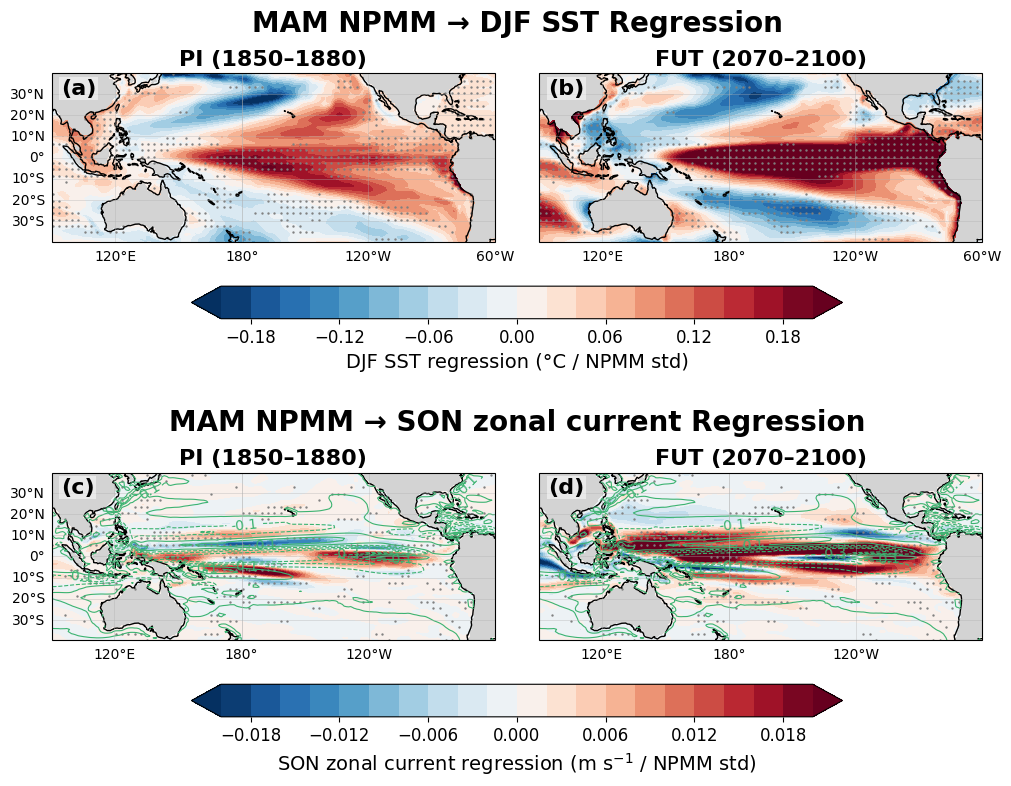

In [16]:
lats_sst = tos_targ_pi.lat
lons_sst = tos_targ_pi.lon
lats_uo  = uo_son_pi.lat
lons_uo  = uo_son_pi.lon

lon2d_sst, lat2d_sst = np.meshgrid(lons_sst, lats_sst)
lon2d_uo,  lat2d_uo  = np.meshgrid(lons_uo,  lats_uo)

fig = plt.figure(figsize=(12,9))
gs  = GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.1)

titles        = ['PI (1850–1880)', 'FUT (2070–2100)']
panel_labels  = ['(a)', '(b)', '(c)', '(d)']

# --- Top row: MAM NPMM → DJF SST ---
sst_data = [reg_sst_pi, reg_sst_fut]
vmax_sst = 0.2
sst_axes = []

# significance of the CHANGE (rank-sum on PI vs FUT per-member slopes) --
# same stippling mask is used on both the PI and FUT panels
sig_mask_sst = p_sst[::3, ::3] < 0.1

for col, (data, title, label) in enumerate(zip(sst_data, titles, panel_labels[:2])):
    reg_map, corr_map, _pooled_p_map = data   # pooled p_map no longer used for stippling
    ax = fig.add_subplot(gs[0, col], projection=ccrs.PlateCarree(central_longitude=180))
    sst_axes.append(ax)

    im_sst = ax.contourf(
        lons_sst, lats_sst, reg_map,
        levels=np.linspace(-vmax_sst, vmax_sst, 21),
        cmap='RdBu_r', extend='both',
        transform=ccrs.PlateCarree()
    )
    ax.scatter(lon2d_sst[::3, ::3][sig_mask_sst], lat2d_sst[::3, ::3][sig_mask_sst],
               c='gray', s=0.5, transform=ccrs.PlateCarree())
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.set_title(title, fontsize=16, fontweight='bold')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
    gl.top_labels    = False
    gl.right_labels  = False
    gl.bottom_labels = True          # lon labels on every panel
    gl.left_labels   = (col == 0)
    ax.text(0.02, 0.97, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

cb_sst = fig.colorbar(im_sst, ax=sst_axes, orientation='horizontal',
                       shrink=0.7, extend='both')
cb_sst.set_label('DJF SST regression (°C / NPMM std)', fontsize=14)
cb_sst.ax.tick_params(labelsize=12)

# --- Bottom row: MAM NPMM → SON zonal current ---
uo_data  = [reg_uo_pi, reg_uo_fut]
vmax_uo = 0.02
uo_axes  = []

sig_mask_uo = p_uo[::3, ::3] < 0.1

for col, (data, title, label) in enumerate(zip(uo_data, titles, panel_labels[2:])):
    reg_map, corr_map, _pooled_p_map = data
    ax = fig.add_subplot(gs[1, col], projection=ccrs.PlateCarree(central_longitude=180))
    uo_axes.append(ax)

    im_uo = ax.contourf(
        lons_uo, lats_uo, reg_map,
        levels=np.linspace(-vmax_uo, vmax_uo, 21),
        cmap='RdBu_r', extend='both',
        transform=ccrs.PlateCarree()
    )

    # --- overlay PI zonal current climatology as contour lines ---
    cs = ax.contour(
        lons_uo, lats_uo, uo_pi_plot,
        levels=np.arange(-.3,.3,.1),   # pick levels that make sense for your units/range
        colors='mediumseagreen', linewidths=.8,
        transform=ccrs.PlateCarree()
    )
    ax.clabel(cs, cs.levels[::2], fontsize=10, fmt='%.1f')  # optional: label every other line

    ax.scatter(lon2d_uo[::3, ::3][sig_mask_uo], lat2d_uo[::3, ::3][sig_mask_uo],
               c='gray', s=0.5, transform=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.set_title(title, fontsize=16, fontweight='bold')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
    gl.top_labels    = False
    gl.right_labels  = False
    gl.bottom_labels = True          # lon labels on every panel
    gl.left_labels   = (col == 0)    # lat labels only on left column (a, c)

    ax.text(0.02, 0.97, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

cb_uo = fig.colorbar(im_uo, ax=uo_axes, orientation='horizontal',
                      shrink=0.7, extend='both')
cb_uo.set_label('SON zonal current regression (m s$^{-1}$ / NPMM std)', fontsize=14)
cb_uo.ax.tick_params(labelsize=12)

# Get x center of the two columns
x_center = (sst_axes[0].get_position().x0 + sst_axes[1].get_position().x1) / 2

fig.text(x_center, sst_axes[0].get_position().y1 + 0.04,
         'MAM NPMM → DJF SST Regression',
         fontsize=20, fontweight='bold', ha='center', va='bottom')

fig.text(x_center, uo_axes[0].get_position().y1 + 0.04,
         'MAM NPMM → SON zonal current Regression',
         fontsize=20, fontweight='bold', ha='center', va='bottom')
plt.savefig('fig_mam_npmm_sst_uo_4panel.png', dpi=150, bbox_inches='tight')
plt.show()